# **ST1519 Agile MLOps CA1 — PBI 2: Hist Gradient Boosting Fraud Model**

**Team member:** Thawdar Lin Wai (Yue Liang)

**Runs:** `HGB_safe` (production-eligible) and `HGB_full` (exploratory leakage check)

---

## **1. Model Objective**

- **Goal:** predict whether an SP-buy order is fraud (`is_fraud = 1`) using information available when the order is assessed
- **Business rule (PO):** prioritise **high precision** while keeping **reasonable recall**, because analysts can only review a limited number of flagged orders
- **Extra check:** compare the safe and full feature sets to see whether the 10 customer snapshot features may leak future information
- **Link to my Logistic Regression:** LR can only learn simple patterns. This model tests whether learning **feature combinations** improves results

## **2. Why Hist Gradient Boosting**

Hist Gradient Boosting builds **many small decision trees one after another**. Each new tree focuses on the orders the previous trees got wrong, and the final fraud score adds all the trees together.

**Why this model:**
- **Learns combinations:** a tree can ask several questions in a row (for example, new account **and** large order **and** high-risk country), which Logistic Regression cannot do
- **Fast for large data:** it groups each feature's values into bins ("histogram"), so it trains quickly on 666,000 orders
- **Handles imbalance:** fraud orders can be given extra weight with `class_weight="balanced"`
- **Strong on tables:** gradient boosting is one of the best model types for tabular data like ours

**Main weaknesses:**
- **Harder to explain:** there are no coefficients, so feature importance has to be measured separately (Section 13)
- **Slower than Logistic Regression:** about 20 seconds instead of 2, but still well within the 3-minute retraining requirement

**Preprocessing:**
- **No scaling needed:** a tree only asks "is this value above or below X", so the size of the numbers does not matter

---

## **3. Setup**

All training code lives in **`src/hist_gradient_boosting.py`**, using the team's shared helpers in **`src/model_utils.py`**.
This notebook only calls those functions, so automated retraining (PBI 5) runs the **same code** without opening the notebook:

```powershell
python src/hist_gradient_boosting.py            # trains HGB_safe + HGB_full and logs to MLflow
```

In [17]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import average_precision_score

# Find the repository root so "src/" can be imported (works from notebooks/ or the root)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_split.py").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import model_utils as mu                       # shared loading / evaluation / MLflow helpers
import hist_gradient_boosting as hgb           # this notebook's model
import logistic_regression as lr               # my LR, for comparison in Section 12
from data_processing import SNAPSHOT_FEATURES  # 10 uncertain customer snapshot features
from data_split import create_split_labels      # team's shared chronological split

%matplotlib inline
# model_utils switches matplotlib to a file-only backend; this turns notebook charts back on

# ---- Configuration (no personal paths or secrets in code) ----
DATA_DIR = os.environ.get("FRAUD_DATA_DIR", REPO_ROOT / "data" / "processed")
OUTPUT_DIR = REPO_ROOT / "outputs"     # local plots/models (not committed)
RUN_SEARCH = True                      # False = skip the search (about 5 minutes) and use the saved settings
LOG_TO_MLFLOW = True                   # uses $MLFLOW_TRACKING_URI, else a local mlruns/ store
DEVELOPER = hgb.DEVELOPER              # "yueliang" unless $MODEL_DEVELOPER is set

pd.set_option("display.float_format", "{:.4f}".format)
print("Repository:", REPO_ROOT)
print("Random seed:", mu.RANDOM_SEED)

Repository: c:\Users\yyuel\OneDrive\Documents\Y2 S2\Agile MLOPs\MLOps_CA1_group5
Random seed: 42


---

## **4. Load and Validate Data**

Both processed files from PBI 1 are loaded and checked:

- **Required columns** exist and `is_fraud` only contains 0 and 1
- **No duplicate orders** (`country_code` + `order_id` is the order key)
- **No missing or infinite values** in any feature
- **Same orders and labels** in both files, in the same order

The **SHA-256 checksum** identifies the exact file version, so the team can confirm everyone used the same data.

In [18]:
safe_path = mu.dataset_path("safe", DATA_DIR)
full_path = mu.dataset_path("full", DATA_DIR)

df_safe = mu.load_feature_data(safe_path)   # raises an error if any check fails
df_full = mu.load_feature_data(full_path)
mu.check_same_orders(df_safe, df_full)

checksums = {"safe": mu.file_sha256(safe_path), "full": mu.file_sha256(full_path)}
pd.DataFrame({
    "rows": [len(df_safe), len(df_full)],
    "columns": [df_safe.shape[1], df_full.shape[1]],
    "features": [len(mu.get_feature_columns(df_safe)), len(mu.get_feature_columns(df_full))],
    "fraud_rate_%": [df_safe["is_fraud"].mean() * 100, df_full["is_fraud"].mean() * 100],
    "sha256": [checksums["safe"][:12], checksums["full"][:12]],
}, index=["safe", "full"])

,rows,columns,features,fraud_rate_%,sha256
safe,949872,36,31,10.9933,656a05ca1189
full,949872,46,41,10.9933,d5abc1ac0ce1


**Observations:**
- **All checks passed:** both files have **949,872 orders** with the same fraud rate (**10.99%**)
- **Safe:** 36 columns = 4 metadata + **31 features** + `is_fraud`
- **Full:** 46 columns = 4 metadata + **41 features** + `is_fraud`

---

## **5. Features**

- **Not model inputs:** `country_code`, `order_id`, `customer_id`, `order_date` (kept for tracking and splitting) and the target `is_fraud`
- **Country is still used** through the one-hot columns (`country_code_BD`, `country_code_MY`, ...)
- **`refund_value` is never a feature:** every fraud order has a refund of 0, so it is recorded after the fraud decision (target leakage)
- **Full dataset:** has 10 extra customer snapshot features that may include activity after the order (Assumption 19)

In [19]:
safe_features = mu.get_feature_columns(df_safe)   # also checks no forbidden column is a feature
full_features = mu.get_feature_columns(df_full)
extra_features = [f for f in full_features if f not in safe_features]

print("Safe features:", len(safe_features))
print("Full features:", len(full_features))
print("Extra features in full = SNAPSHOT_FEATURES:", sorted(extra_features) == sorted(SNAPSHOT_FEATURES))
print("refund_value in either dataset:", "refund_value" in df_safe.columns or "refund_value" in df_full.columns)

Safe features: 31
Full features: 41
Extra features in full = SNAPSHOT_FEATURES: True
refund_value in either dataset: False


**Observations:**
- The 10 extra features in the full file are **exactly** the snapshot features from Assumption 19
- `refund_value` is in **neither** file, so there is no target leakage from refunds

---

## **6. Shared Chronological Split**

`create_split_labels()` from `src/data_split.py` is reused, so every teammate and both datasets use **the same orders**:

- **Train:** up to 15 Mar 2023, used to fit the model
- **Validation:** 16 Mar to 13 Apr 2023, used to choose hyperparameters, when to stop adding trees, and the threshold
- **Test:** from 14 Apr 2023, used **once** for the final scores

The split is by date because the model will be used on **future** orders.

In [20]:
split = create_split_labels(df_safe)
assert split.equals(create_split_labels(df_full)), "Safe and full splits differ!"

split_summary = (df_safe.assign(split=split)
                 .groupby("split")
                 .agg(first_date=("order_date", "min"), last_date=("order_date", "max"),
                      orders=("is_fraud", "size"), fraud_orders=("is_fraud", "sum"),
                      fraud_rate=("is_fraud", "mean"))
                 .loc[["Train", "Validation", "Test"]])
split_summary["share_%"] = split_summary["orders"] / len(df_safe) * 100
split_summary

,first_date,last_date,orders,fraud_orders,fraud_rate,share_%
split,,,,,,
Train,2022-11-12,2023-03-15,665876,67594,0.1015,70.1017
Validation,2023-03-16,2023-04-13,139874,18993,0.1358,14.7256
Test,2023-04-14,2023-05-11,144122,17835,0.1237,15.1728


**Observations:**
- **Train:** 665,876 orders (70.1%), fraud rate **10.15%**
- **Validation:** 139,874 orders (14.7%), fraud rate **13.58%**
- **Test:** 144,122 orders (15.2%), fraud rate **12.37%**
- The fraud rate is **higher in later periods**, so the data changes over time

---

## **7. Evaluation Method and Threshold Rule**

### **7.1 Metrics**

| Metric | Simple meaning |
|---|---|
| **Precision** | When the model flags an order, how often is it really fraud? |
| **Recall** | Out of all fraud orders, how many did the model catch? |
| **F1** | One score that balances precision and recall |
| **PR-AUC** | How well the model ranks fraud above normal orders overall. Does not depend on the threshold |

- **Precision is the primary metric** (team standard): analysts can only review a limited number of orders, so flagged orders must usually be fraud
- **Recall is the secondary metric:** once precision is high enough, catch as much fraud as possible
- **PR-AUC is used to compare models across the team:** teammates may use different threshold rules, so precision alone is not a fair comparison. PR-AUC does not depend on the threshold. A random guess scores about **0.12** (the fraud rate)
- **Accuracy is not used:** saying "not fraud" for every order would already be about **88%** correct, while catching zero fraud

### **7.2 Threshold Rule**

The model gives each order a **fraud probability** from 0 to 1. The **threshold** is the cut-off: orders above it are flagged as fraud.

| Threshold | What happens |
|---|---|
| **Low** | Flags many orders, catches more fraud, but also flags more genuine customers |
| **High** | Flags fewer orders, most are real fraud, but more fraud is missed |

**Rule used (same as my Logistic Regression):**
1. **Precision must be at least 70%**, so at least **7 in 10 flagged orders are real fraud** (primary metric)
2. Among the thresholds that meet this, pick the one that **catches the most fraud** (secondary metric: recall)

**Why this rule:**
- **Matches the PO and the team standard:** precision first, then recall
- **Not just the highest precision:** that would only flag a

In [21]:
print("Threshold rule:", hgb.THRESHOLD_RULE)
print("Precision target:", hgb.PRECISION_TARGET)

Threshold rule: highest recall with validation precision >= 70%
Precision target: 0.7


---

## **8. Hyperparameter Search**

16 models are trained on **safe Train** and scored on **safe Validation**. The test set is not used.

| Hyperparameter | Values tried | Why |
|---|---|---|
| `learning_rate` | 0.05, 0.1 | How big a step each new tree takes. Smaller steps need more trees but can be more accurate |
| `max_leaf_nodes` | 31, 63 | How complex each tree can be. More leaves = more detailed patterns, but more risk of overfitting |
| `l2_regularization` | 0, 1 | Penalty that keeps the trees simpler |
| `class_weight` | None, balanced | Whether giving fraud orders more weight helps with the class imbalance |
| `min_samples_leaf` | fixed: 50 | Each leaf must contain at least 50 orders, so trees do not learn from a handful of orders |
| `max_iter` | fixed: 500 | Upper limit on the number of trees |
| early stopping | fixed: 20 rounds | Stop adding trees when the validation log-loss has not improved for 20 rounds |
| `random_state` | fixed: 42 | Same results every run |

**Early stopping** uses the **chronological validation period**, so the number of trees is chosen on orders after the training period (the same idea as the team's MLP).

**Ranking:** by validation **PR-AUC**. Recall at 70% precision is also shown, since that is how the model will be used.

In [22]:
if RUN_SEARCH:
    tuning_table, params = hgb.tune(df_safe)
    if LOG_TO_MLFLOW:
        mu.log_tuning_table(tuning_table, "hist_gradient_boosting_tuning", developer=DEVELOPER)
    display(tuning_table)
else:
    params = hgb.SELECTED_PARAMS

print("Selected hyperparameters:", params)
print("Same as SELECTED_PARAMS saved in src/hist_gradient_boosting.py:", params == hgb.SELECTED_PARAMS)

[MLflow] No shared server configured -> LOCAL testing store: sqlite:///C:/Users/yyuel/OneDrive/Documents/Y2 S2/Agile MLOPs/MLOps_CA1_group5/mlruns/mlflow.db


,learning_rate,max_leaf_nodes,l2_regularization,class_weight,trees_used,val_average_precision,val_roc_auc,val_recall_at_70%_precision,train_average_precision,train_seconds
0,0.1000,63,1.0000,None,110,0.5340,0.8530,0.1411,0.4633,8.2500
1,0.1000,63,0.0000,None,101,0.5340,0.8531,0.1309,0.4626,7.7900
2,0.0500,63,1.0000,None,205,0.5339,0.8530,0.1396,0.4627,21.6000
3,0.0500,63,0.0000,None,155,0.5337,0.8534,0.1363,0.4591,12.7900
4,0.0500,31,1.0000,balanced,500,0.5337,0.8526,0.1428,0.4588,30.3800
5,0.0500,31,0.0000,balanced,500,0.5331,0.8529,0.1361,0.4583,20.5200
6,0.0500,63,0.0000,balanced,500,0.5325,0.8508,0.1396,0.4716,37.0000
7,0.0500,31,0.0000,None,252,0.5325,0.8533,0.1316,0.4553,17.0100
8,0.0500,31,1.0000,None,236,0.5324,0.8531,0.1335,0.4544,13.2100
9,0.0500,63,1.0000,balanced,500,0.5323,0.8510,0.1392,0.4703,34.9400


Selected hyperparameters: {'learning_rate': 0.1, 'max_leaf_nodes': 63, 'l2_regularization': 1.0, 'class_weight': None, 'min_samples_leaf': 50, 'max_iter': 500, 'early_stopping': True, 'scoring': 'loss', 'n_iter_no_change': 20, 'random_state': 42}
Same as SELECTED_PARAMS saved in src/hist_gradient_boosting.py: True


### **Observations**

- **Similar performance across all 16 settings:** Validation PR-AUC ranges from **0.528 to 0.534**, indicating that HGB is relatively insensitive to the tested hyperparameter settings on this dataset.

#### **Selected Hyperparameters**

| Parameter | Selected Value |
| :--- | :--- |
| `learning_rate` | 0.1 |
| `max_leaf_nodes` | 63 |
| `l2_regularization` | 1.0 |
| `class_weight` | None |
| **Validation PR-AUC** | **0.5340** |

The selected configuration achieved the highest validation PR-AUC and is saved as `SELECTED_PARAMS` in `src/hist_gradient_boosting.py`.

- **Effective early stopping:** The selected model stopped at **110 out of 500 trees** and completed training in approximately **10 seconds**.

- **Class weighting did not improve performance:** Models using `class_weight="balanced"` trained for all **500 trees**, took approximately **3 times longer**, and did not achieve higher validation PR-AUC.

- **Training vs. validation PR-AUC:** Validation PR-AUC (0.53) is higher than training PR-AUC (0.46). This may be partly explained by the higher fraud rate in the validation set (13.6%) compared to the training set (10.2%), as PR-AUC is sensitive to class prevalence. This difference alone does not indicate a modelling problem.

---

## **9. Model Training**

### **9.1 Safe Dataset (HGB_safe)**

`mu.run_training()` does the same steps for every run:

1. Split with the shared chronological function
2. Train on **Train** only (validation is only used to decide when to stop adding trees)
3. Choose the threshold on **Validation** with the 70% precision rule
4. Score **Test** once with that threshold
5. Save plots and the model locally, and log everything to MLflow

`HGB_safe` is the **production-eligible** run.

In [23]:
mlflow_location = mu.setup_mlflow() if LOG_TO_MLFLOW else None
common = dict(output_dir=OUTPUT_DIR, mlflow_location=mlflow_location, developer=DEVELOPER,
              snapshot_features=SNAPSHOT_FEATURES, trusted_types=hgb.TRUSTED_TYPES)

result_safe, model_safe = mu.run_training(
    hgb.ALGORITHM, hgb.SHORT_NAME, "safe", df_safe, hgb.train_model, params,
    hgb.feature_importance, dataset_sha256=checksums["safe"],
    threshold_fn=hgb.choose_threshold_min_precision, threshold_rule=hgb.THRESHOLD_RULE, **common)

print(f"Threshold chosen on validation: {result_safe['threshold']:.4f}")
print(f"Trees used (early stopping): {model_safe.n_iter_} of {params['max_iter']}")
print(f"Training time: {result_safe['train_seconds']:.1f} s")

[MLflow] No shared server configured -> LOCAL testing store: sqlite:///C:/Users/yyuel/OneDrive/Documents/Y2 S2/Agile MLOPs/MLOps_CA1_group5/mlruns/mlflow.db
Threshold chosen on validation: 0.5805
Trees used (early stopping): 110 of 500
Training time: 11.0 s


### **9.2 Full Dataset (HGB_full)**

- **Same** hyperparameters, seed, split and **threshold** as `HGB_safe`
- The **only** difference is the 10 snapshot features, so any change in results comes from them
- Tagged `exploratory=true` and `production_eligible=false` in MLflow, so it must **never** be registered or promoted

In [24]:
result_full, model_full = mu.run_training(
    hgb.ALGORITHM, hgb.SHORT_NAME, "full", df_full, hgb.train_model, params,
    hgb.feature_importance, threshold=result_safe["threshold"],   # reuse the safe threshold
    dataset_sha256=checksums["full"], **common)

print(f"Threshold reused: {result_full['threshold']:.4f}")
print(f"Trees used (early stopping): {model_full.n_iter_} of {params['max_iter']}")
print(f"Training time: {result_full['train_seconds']:.1f} s")

Threshold reused: 0.5805
Trees used (early stopping): 105 of 500
Training time: 11.3 s


---

## **10. Validation Results and Threshold Check**

Validation results of `HGB_safe` at the chosen threshold, compared with the scikit-learn default threshold of 0.5.

In [25]:
parts, _ = mu.split_data(df_safe)
X_train, y_train = parts["Train"]
X_val, y_val = parts["Validation"]
X_test, y_test = parts["Test"]
val_prob = model_safe.predict_proba(X_val)[:, 1]

threshold_check = pd.DataFrame({
    f"chosen ({result_safe['threshold']:.4f})": mu.evaluate(y_val, val_prob, result_safe["threshold"]),
    "sklearn default (0.5)": mu.evaluate(y_val, val_prob, 0.5),
}).loc[["precision", "recall", "f1", "average_precision", "tp", "fp"]]
threshold_check.loc["orders_flagged"] = threshold_check.loc["tp"] + threshold_check.loc["fp"]
threshold_check.round(4)

,chosen (0.5805),sklearn default (0.5)
precision,0.7001,0.6642
recall,0.1411,0.1937
f1,0.2349,0.2999
average_precision,0.5340,0.5340
tp,2680.0000,3679.0000
fp,1148.0000,1860.0000
orders_flagged,3828.0000,5539.0000


**Observations:**

| | Chosen (0.5805) | sklearn default (0.5) | Difference |
|---|---|---|---|
| **Orders flagged** | 3,828 | 5,539 | +1,711 |
| **Real fraud caught** | 2,680 | 3,679 | +999 |
| **Genuine customers wrongly flagged** | 1,148 | 1,860 | +712 |
| **Precision** | 70.0% | 66.4% | lower |
| **Recall** | 14.1% | 19.4% | higher |

- **Chosen threshold (0.5805):** 7 in 10 flagged orders are real fraud, and it catches about 1 in 7 fraud orders
- **Default 0.5:** flags 1,711 more orders, which catches 999 more fraud but also wrongly flags 712 more genuine customers
- **The extra orders are lower quality:** only about 58% of the extra 1,711 orders are fraud, compared with 70% for the orders the chosen threshold flags. This is why precision drops
- **The rule picks 0.5805 because 0.5 misses the 70% precision target** (66.4%)

**Analysis:**
- **Why 0.5 is close here but not for my Logistic Regression:** my LR used `class_weight="balanced"`, which pushes all probabilities up, so at 0.5 it flagged 44,139 orders with only 32% precision. This model uses `class_weight=None`, so its probabilities are not pushed up, and 0.5 already flags only high-risk orders
- **Business trade-off:** going from 0.5805 to 0.5 would catch 999 more fraud orders for 712 more false alarms. Whether that is worth it is a decision for the PO. The 70% rule keeps analysts' workload focused on the most likely fraud
- **PR-AUC is the same (0.5340) for both:** it measures how well the model ranks orders overall, so changing the threshold does not affect it

---

## **11. Test Results**

Results on the **test** period (14 Apr to 11 May 2023), which was not used for any decision.

In [26]:
results = [result_safe, result_full]
comparison = mu.comparison_table(results)
comparison

,HGB_safe,HGB_full
Accuracy,0.8812,0.8831
Precision (fraud),0.5676,0.5481
Recall (fraud),0.1678,0.3142
F1 (fraud),0.2590,0.3994
Average precision,0.4251,0.5089
ROC-AUC,0.8119,0.8770
TP,2993,5604
FP,2280,4620
FN,14842,12231
TN,124007,121667


**How to read this table:**

| Row | Meaning |
|---|---|
| **TP** (true positive) | Fraud, and the model flagged it (caught) |
| **FP** (false positive) | Not fraud, but the model flagged it (false alarm) |
| **FN** (false negative) | Fraud, but the model missed it |
| **TN** (true negative) | Not fraud, and the model left it alone |
| **Production eligible** | Only HGB_safe can be used for real, since HGB_full uses the uncertain snapshot features |

**Observations (HGB_safe on test):**

| | Fraud orders | Genuine orders |
|---|---|---|
| **Flagged by the model** | 2,993 (caught) | 2,280 (false alarm) |
| **Not flagged** | 14,842 (missed) | 124,007 (correctly left alone) |
| **Total** | 17,835 | 126,287 |

- **For analysts:** 5,273 orders were flagged. Out of every 10 they review, almost **6 are real fraud** (precision 56.8%), about **4.6 times** better than picking orders at random (fraud rate 12.4%)
- **For genuine customers:** only **1.8%** of genuine orders (2,280 of 126,287) were wrongly flagged, so most honest customers are not disturbed
- **For fraud:** the model catches about **1 in 6** fraud orders (recall 16.8%), and **14,842** fraud orders are still missed
- **Precision is below the 70% target** that was set on validation. This drop is explained after the charts below

**Analysis:**
- **High precision, low recall is the trade-off we chose:** the strict threshold keeps analysts focused on the most likely fraud, but most fraud gets through. A lower threshold would catch more fraud, but analysts would review more genuine orders
- **Accuracy 88.1% is misleading:** saying "not fraud" for every order would already score 87.6%, because almost 9 in 10 orders are genuine. That is why precision and recall are used instead
- **Fast enough for retraining:** trains in about 12 seconds and scores all 144,122 test orders in under 1 second, well within the 3-minute pipeline requirement
- **HGB_full** is only for the leakage check (Section 13), so it is not compared here

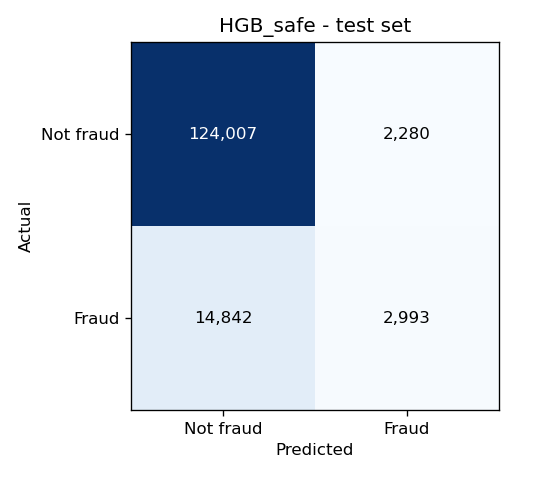

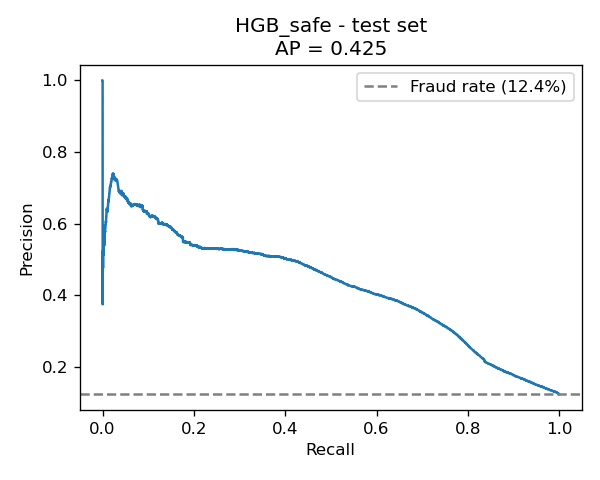

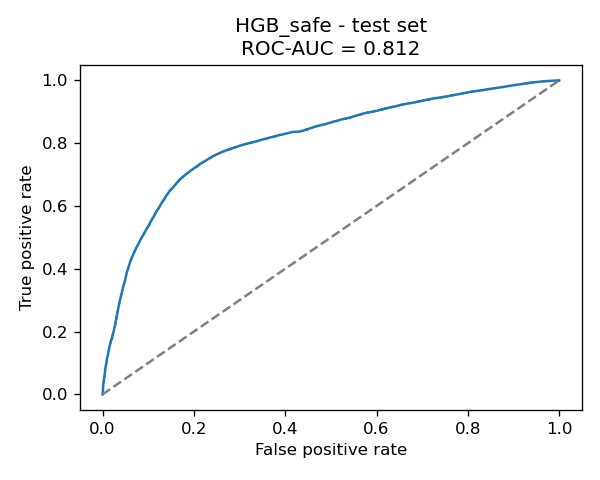

In [27]:
plots = OUTPUT_DIR / "HGB_safe" / "plots"
display(Image(plots / "confusion_matrix_test.png"), Image(plots / "precision_recall_test.png"),
        Image(plots / "roc_test.png"))

In [28]:
# Same model, same threshold: compare validation and test side by side
X_test, y_test = parts["Test"]
test_prob = model_safe.predict_proba(X_test)[:, 1]

val_vs_test = pd.DataFrame({
    "Validation": mu.evaluate(y_val, val_prob, result_safe["threshold"]),
    "Test": mu.evaluate(y_test, test_prob, result_safe["threshold"]),
}).loc[["precision", "recall", "average_precision", "tp", "fp"]]
val_vs_test.loc["orders_flagged"] = val_vs_test.loc["tp"] + val_vs_test.loc["fp"]
val_vs_test["change"] = val_vs_test["Test"] - val_vs_test["Validation"]

# show counts as whole numbers and scores with 4 decimals
shown = val_vs_test.round(4).astype(object)
for row in ["tp", "fp", "orders_flagged"]:
    shown.loc[row] = val_vs_test.loc[row].astype(int)
shown

,Validation,Test,change
precision,0.7001,0.5676,-0.1325
recall,0.1411,0.1678,0.0267
average_precision,0.5340,0.4251,-0.1089
tp,2680,2993,313
fp,1148,2280,1132
orders_flagged,3828,5273,1445


**Validation vs Test (HGB_safe):**

| | Validation | Test | Change |
|---|---|---|---|
| **Precision** | 0.700 | 0.568 | lower |
| **Recall** | 0.141 | 0.168 | higher |
| **PR-AUC** | 0.534 | 0.425 | lower |
| **Orders flagged** | 3,828 | 5,273 | more |

- **Precision dropped from 70% to 57%:** the threshold was chosen on mid-March to mid-April orders, but the fraud pattern changed in the test period (**data drift**)
- **Recall went up only because more orders were flagged**, not because the model got better
- **PR-AUC fell from 0.534 to 0.425**, a bigger drop than my Logistic Regression (0.461 to 0.398)
- **This is why regular retraining (PBI 5) matters:** the model needs to learn from recent orders to keep up

---

## **12. Comparison with My Logistic Regression**

Did learning feature combinations help? My Logistic Regression is retrained here with its saved settings (about 2 seconds, **not logged** to MLflow), and both models are scored on the **same** validation and test orders with the **same** 70% precision rule.

In [29]:
lr_model, _ = lr.train_model(X_train, y_train, X_val, y_val, lr.SELECTED_PARAMS)
lr_val_prob = lr_model.predict_proba(X_val)[:, 1]
lr_threshold = lr.choose_threshold_min_precision(y_val, lr_val_prob)

rows = {}
for name, model, threshold in [("LR_safe", lr_model, lr_threshold),
                               ("HGB_safe", model_safe, result_safe["threshold"])]:
    val_p = model.predict_proba(X_val)[:, 1]
    test_p = model.predict_proba(X_test)[:, 1]
    test_m = mu.evaluate(y_test, test_p, threshold)
    rows[name] = {
        "val_pr_auc": average_precision_score(y_val, val_p),
        "test_pr_auc": average_precision_score(y_test, test_p),
        "val_recall_at_70%_precision": hgb.recall_at_precision(y_val, val_p),
        "test_recall_at_70%_precision": hgb.recall_at_precision(y_test, test_p),
        "test_precision (val threshold)": test_m["precision"],
        "test_recall (val threshold)": test_m["recall"],
        "test_orders_flagged": test_m["tp"] + test_m["fp"],
    }
model_comparison = pd.DataFrame(rows)
model_comparison["HGB - LR"] = model_comparison["HGB_safe"] - model_comparison["LR_safe"]
model_comparison

,LR_safe,HGB_safe,HGB - LR
val_pr_auc,0.4610,0.5340,0.0730
test_pr_auc,0.3975,0.4251,0.0276
val_recall_at_70%_precision,0.1190,0.1411,0.0221
test_recall_at_70%_precision,0.0063,0.0320,0.0257
test_precision (val threshold),0.6062,0.5676,-0.0386
test_recall (val threshold),0.1831,0.1678,-0.0153
test_orders_flagged,5386.0000,5273.0000,-113.0000


**Observations:**

| | LR_safe | HGB_safe | Better |
|---|---|---|---|
| **Validation PR-AUC** | 0.461 | 0.534 | HGB (+0.073) |
| **Test PR-AUC** | 0.398 | 0.425 | HGB (+0.028) |
| **Test precision** (validation threshold) | 0.606 | 0.568 | LR |
| **Test recall** (validation threshold) | 0.183 | 0.168 | LR |

- **HGB ranks fraud better overall:** higher PR-AUC on both validation and test, so learning **feature combinations helps**
- **But its advantage shrinks on test** (+0.073 to +0.028). A more complex model learns more detailed patterns from the training period, and more of those patterns stop working when fraud changes
- **At the 70% threshold, LR did slightly better on test:** both thresholds were set on validation, and HGB's precision dropped more after the drift
- **Neither model reaches 70% precision on test in a useful way:** even with the best possible threshold, only **3.2%** (HGB) and **0.6%** (LR) of test fraud could be caught at 70% precision
- **Conclusion:** HGB is the better model by the team's main metric (**PR-AUC**), but the drift affects both models, so retraining matters more than which of the two is used

---

## **13. Safe versus Full Comparison**

,HGB_safe,HGB_full,full - safe
Precision (fraud),0.5676,0.5481,-0.0195
Recall (fraud),0.1678,0.3142,0.1464
F1 (fraud),0.2590,0.3994,0.1404
Average precision,0.4251,0.5089,0.0837
ROC-AUC,0.8119,0.8770,0.0650


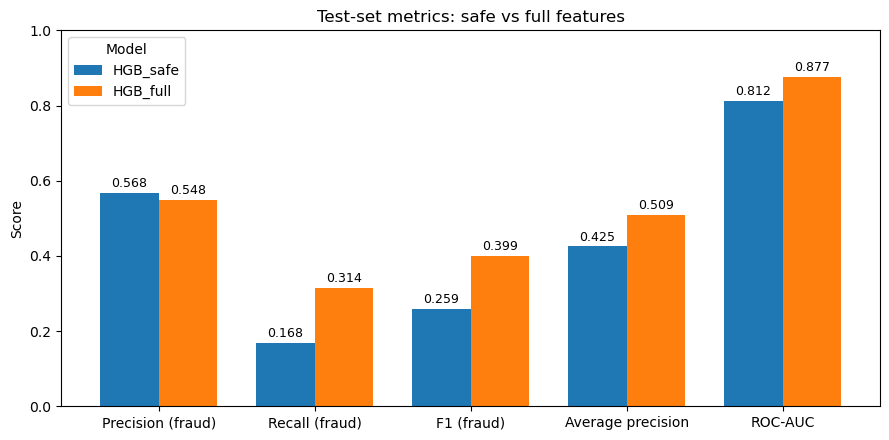

In [30]:
metrics = ["Precision (fraud)", "Recall (fraud)", "F1 (fraud)", "Average precision", "ROC-AUC"]
diff = comparison.loc[metrics].astype(float)
diff["full - safe"] = diff["HGB_full"] - diff["HGB_safe"]
display(diff.round(4))

ax = diff[["HGB_safe", "HGB_full"]].plot.bar(figsize=(9, 4.5), rot=0, width=0.75)
for bars in ax.containers:                      # one container per model (safe, full)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
ax.set_title("Test-set metrics: safe vs full features")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model", loc="upper left")
plt.tight_layout()
plt.show()

**Observations:**

| | HGB_safe (31 features) | HGB_full (41 features) | Difference |
|---|---|---|---|
| **PR-AUC** | 0.425 | 0.509 | **+0.084** |
| **ROC-AUC** | 0.812 | 0.877 | **+0.065** |
| **Recall** | 0.168 | 0.314 | about double |
| **Precision** | 0.568 | 0.548 | slightly lower |

- **Adding the 10 snapshot features makes the model score clearly higher**, with a bigger gain than for my Logistic Regression (+0.052 PR-AUC)
- **Precision is lower** because HGB_full uses the same threshold as HGB_safe, so it flags more orders
- **Question:** are the snapshot features genuinely useful, or do they contain **future information** the model should not have? Section 13.1 checks this

### **13.1 Data Leakage Check by Month**

- A higher score with the full features does **not** prove leakage, since the features might simply be useful
- If the snapshot was taken around **11 May 2023**, its "last 50 days" window covers about **22 Mar to 11 May**
- If the snapshot features leak, their advantage should **grow for orders closer to the snapshot date**
- Only months the model never trained on (after 15 Mar) are used

,month,orders,fraud_rate_%,safe_AP,full_AP,gain_full_minus_safe
0,2023-03,77691,13.9400,0.5610,0.5822,0.0212
1,2023-04,148855,12.6100,0.4440,0.5121,0.0681
2,2023-05,57450,12.5700,0.4497,0.5331,0.0834


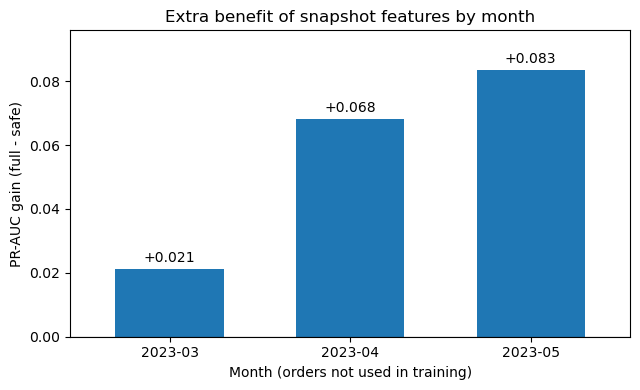

In [31]:
by_month = mu.gain_by_month(model_safe, model_full, df_safe, df_full)
display(by_month)

ax = by_month.plot(x="month", y="gain_full_minus_safe", kind="bar", legend=False,
                   rot=0, figsize=(6.5, 4), width=0.6)
ax.bar_label(ax.containers[0], fmt="%+.3f", padding=3, fontsize=10)   # value on each bar
ax.axhline(0, color="black", linewidth=0.8)
ax.margins(y=0.15)                                                     # room for the labels
ax.set_xlabel("Month (orders not used in training)")
ax.set_ylabel("PR-AUC gain (full - safe)")
ax.set_title("Extra benefit of snapshot features by month")
plt.tight_layout()
plt.show()

**Observations:**

| Month (not used in training) | Extra PR-AUC from snapshot features |
|---|---|
| **March** (16th to 31st) | **+0.021** (least help) |
| **April** | **+0.068** |
| **May** (1st to 11th) | **+0.083** (most help) |

- **The closer the orders are to May, the more the snapshot features help**, the same pattern as my Logistic Regression
- **Why this matters:** the snapshot was likely taken around 11 May. If it contains activity that happened after an order, it would help most for orders close to that date, which is exactly what we see
- **This points to leakage**, but is **not proof**, since fraud patterns also change over time and the snapshot date cannot be confirmed
- **Two different models showing the same pattern** makes the evidence stronger
- **Decision:** the snapshot features stay **out of the production model** (Assumption 19)

**Analysis:**

| Month | Safe model PR-AUC | Full model PR-AUC | Gain | Gain as % of safe |
|---|---|---|---|---|
| **March** | 0.561 | 0.582 | +0.021 | about 4% |
| **April** | 0.444 | 0.512 | +0.068 | about 15% |
| **May** | 0.450 | 0.533 | +0.083 | about 19% |

- **Two parts to the gain:**
  - **A small steady part** (about +0.02 in March) may be genuinely useful information, such as a customer's general purchase history
  - **The growing part** (up to about +0.06 more by May) is the suspicious part, since it only appears as orders get closer to the snapshot date
- **HGB gains more than LR** (+0.083 vs +0.048 in May). HGB can combine features, so it can make more use of any future information hidden in the snapshot features
- **The full model's results are likely too optimistic:** HGB_full's test PR-AUC of 0.509 would probably not hold in real use, so **HGB_safe's 0.425 is the more honest estimate** of real performance
- **Real-world risk:** in production, the snapshot features would be calculated when the order comes in, without any future activity. A model trained with future information would then perform worse than its test results suggest
- **The safe model also gets worse over time** (0.561 in March to about 0.45 in April and May) without any snapshot features. This is the **data drift** seen in Section 11, and it is separate from the leakage

**Recommendation:**
- Ask the data owner for the **exact snapshot date**, or for customer history with dates, so these features can be calculated **as of each order's date**. Then they could be used safely
- Until then, keep the snapshot features **out** of all production models

---

## **14. Feature Importance (Permutation)**

Trees have **no coefficients**, so importance is measured by **permutation**:

1. Take 20,000 validation orders
2. Randomly **shuffle one feature**, which breaks its link to fraud
3. Measure how much **PR-AUC drops**. A big drop means the model relies on that feature
4. Repeat 3 times per feature and take the average

Unlike coefficients, this only shows **how much** a feature matters, not whether it raises or lowers the risk.

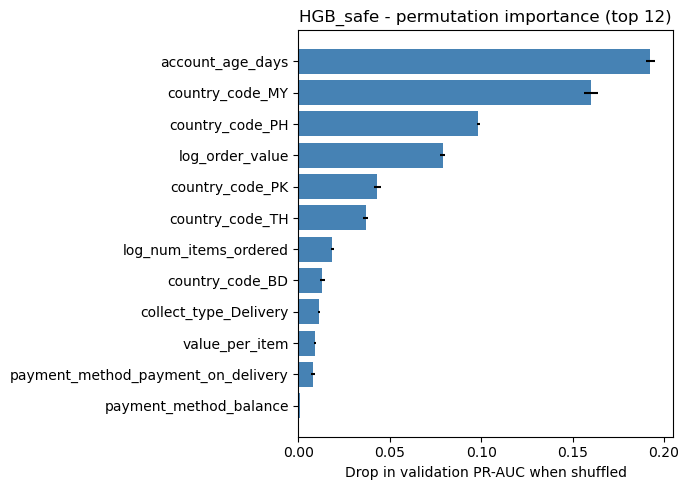

,feature,importance,std
0,account_age_days,0.1925,0.0026
1,country_code_MY,0.1600,0.0038
2,country_code_PH,0.0985,0.0010
3,log_order_value,0.0789,0.0013
4,country_code_PK,0.0432,0.0018
5,country_code_TH,0.0367,0.0012
6,log_num_items_ordered,0.0184,0.0009
7,country_code_BD,0.0131,0.0014
8,collect_type_Delivery,0.0113,0.0006
9,value_per_item,0.0091,0.0004


In [32]:
importance = result_safe["importance"]
top = importance.head(12).sort_values("importance")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="steelblue")
ax.set_xlabel("Drop in validation PR-AUC when shuffled")
ax.set_title("HGB_safe - permutation importance (top 12)")
plt.tight_layout()
plt.show()

importance.head(12)

**Observations:**

| Rank | Feature | PR-AUC drop when shuffled |
|---|---|---|
| 1 | `account_age_days` | 0.193 |
| 2 | `country_code_MY` | 0.160 |
| 3 | `country_code_PH` | 0.099 |
| 4 | `log_order_value` | 0.079 |
| 5 | `country_code_PK` | 0.043 |
| 6 | `country_code_TH` | 0.037 |

- **Account age is the most important feature:** shuffling it lowers validation PR-AUC by about **0.19**
- **Country is the most important group:** 4 of the top 6 features are countries
- **Payment method and collection type barely matter** (all below 0.012)
- **Small error bars:** the 3 repeats give very similar results, so the ranking is reliable

**Analysis:**
- **Same main signals as Logistic Regression:** account age, country and order value come out on top in both models, so the two models agree on what matters
- **Some countries rank differently:** `country_code_PH` is 3rd here but had a small coefficient in LR, while `country_code_BD` had a large LR coefficient but ranks 8th here. Trees can use a country together with other features, so a country can matter more or less than it does on its own
- **No direction:** permutation importance shows **how much** a feature matters, not whether it raises or lowers the risk. The LR coefficients (in my LR notebook) show the direction
- **Linked, not caused:** these are patterns in the data. Flagged orders should be reviewed by analysts, not blocked automatically, to avoid unfairly flagging genuine customers from certain countries

---

## **15. MLflow Experiment Tracking**

Logging uses the team's shared **`src/mlflow_utils.py`** through `model_utils`:

- **Experiment:** `SP-buy-Fraud-Detection`
- **Run names:** `{member}_{algorithm}_{dataset_version}_{model_version}`, e.g. `yueliang_hist_gradient_boosting_safe_v1`
- **Tags:** `team_member`, `algorithm`, `dataset_version`, `model_version`, `production_eligible`, `exploratory`
- **Parameters:** hyperparameters, threshold, threshold rule, feature count, dataset SHA-256, row counts
- **Metrics:** validation and test metrics, TP/TN/FP/FN, trees used, training and inference time
- **Artifacts:** confusion matrix, PR and ROC curves, feature importance (plot and CSV), and the model with its signature
- **Model format:** saved in MLflow's safe format, which needs `TreePredictor` listed as a trusted type

The server address is read from **`MLFLOW_TRACKING_URI`**, so nothing is hard-coded. If it is not set, runs go to a local test store (`mlruns/`, git-ignored).

In [33]:
for r in results:
    print(f"{mu.mlflow_run_name(r):<45} run_id={r.get('mlflow_run_id', 'not logged')}  "
          f"production_eligible={r['production_eligible']}  location={mlflow_location}")

yueliang_hist_gradient_boosting_safe_v1       run_id=19e747954af44ecdbaf904adbc0abb1c  production_eligible=True  location=local
yueliang_hist_gradient_boosting_full_v1       run_id=0c3f3cecfae44f708973aab9bf5ea317  production_eligible=False  location=local


---

## **16. Summary**

**Final model: HGB_safe** (`learning_rate=0.1`, `max_leaf_nodes=63`, `l2_regularization=1.0`, `class_weight=None`, 110 trees, threshold **0.5805**)

**Results (test period 14 Apr to 11 May 2023)**

| | HGB_safe | HGB_full | LR_safe (for reference) |
|---|---|---|---|
| **PR-AUC (average precision)** | **0.425** | 0.509 | 0.398 |
| **ROC-AUC** | 0.812 | 0.877 | 0.772 |
| **Fraud precision** | 0.568 | 0.548 | 0.606 |
| **Fraud recall** | 0.168 | 0.314 | 0.183 |
| **Fraud F1** | 0.259 | 0.399 | 0.281 |
| **Threshold** | 0.5805 | 0.5805 (reused) | 0.8596 |
| **Training time** | about 12 s (110 trees) | about 14 s | about 2 s |
| **Production eligible** | **Yes** | No (exploratory) | **Yes** |

- HGB values are from this notebook's run, and LR_safe values are from my Logistic Regression notebook (same data, split and threshold rule)
- **HGB_full is not a real option:** its higher scores likely come from leaked snapshot features (Section 13.1)

**Validation vs Test (HGB_safe)**

| | Validation | Test |
|---|---|---|
| **Precision** | 0.700 | 0.568 |
| **Recall** | 0.141 | 0.168 |
| **F1** | 0.235 | 0.259 |
| **PR-AUC** | 0.534 | 0.425 |
| **ROC-AUC** | 0.853 | 0.812 |

- **Validation precision is 0.700 by design:** the threshold rule lowers the threshold as far as possible while keeping precision at 70%, so it always lands at the edge. **Test precision is the real check**
- **Every score is lower on test except recall**, which rose only because more orders were flagged (data drift, Section 11)

**What the model learned:**
- **Most important features:** account age, country (Malaysia, Philippines, Pakistan, Thailand) and order value
- **Same main signals as my Logistic Regression**, so both models agree on what matters
- **Some countries rank differently** because trees use a country together with other features
- **Full explanation and cautions:** see Section 14 (Analysis)

**What this means for the business:**
- **Analyst workload:** over the 4-week test period, the model flagged **5,273** orders (about **190 per day**)
- **Useful flags:** almost **6 in 10** flagged orders are real fraud, compared with about 1 in 8 if orders were picked at random
- **Genuine customers:** only **1.8%** of genuine orders were wrongly flagged, so most honest customers are not disturbed
- **Missed fraud:** about **5 in 6** fraud orders are still not flagged, so this model alone cannot stop most fraud
- **Trade-off:** on validation, lowering the threshold to 0.5 would catch 999 more fraud orders but wrongly flag 712 more genuine customers, and precision would fall below the 70% target. Whether that is worth it is a decision for the PO

**Key findings:**
- **Better than Logistic Regression at ranking fraud:** higher PR-AUC on validation (0.534 vs 0.461) and test (0.425 vs 0.398), and at the same 70% validation precision it catches more fraud (14.1% vs 11.9%). Learning feature combinations helps
- **But its lead shrinks on newer orders:** a more detailed model learns more patterns from the training period, and more of them stop working when fraud changes. At the 70% threshold, LR's test precision and recall were slightly higher
- **Data drift:** precision dropped from 70% to 57% on test, more than LR's drop (70% to 61%), so **regular retraining (PBI 5)** matters
- **Leakage check:** the snapshot features help more as orders get closer to May (+0.021 to +0.083), the same pattern as LR. HGB_full's higher score is likely too optimistic, so the snapshot features stay out (Assumption 19)
- **Fast:** trains in about 12 seconds and scores 144,122 orders in under 1 second, well within the 3-minute retraining requirement
- **Hyperparameters barely matter:** all 16 settings scored within 0.007 PR-AUC, and `class_weight="balanced"` only made training slower

**Limitations:**
- **Harder to explain:** no coefficients, and permutation importance does not show whether a feature raises or lowers the risk
- **Threshold rule:** neither model reached 70% precision on test in a useful way, so the team may need to review the target or retrain more often
- **One time split:** results on other time periods may differ
- **Early stopping uses the validation period:** the test set stays untouched, but validation is used for stopping, choosing settings and the threshold
- **`account_age_days`** comes from the customer table, so its timing has not been formally confirmed
- **Fairness:** country has a strong effect, so flagged orders should be reviewed by analysts, not blocked automatically

**Overall conclusion:**
- **HGB_safe is my stronger model** by the team's comparison metric (PR-AUC), so it is my candidate for the model registry
- **LR_safe is a useful backup:** simpler, easier to explain, and its precision held up slightly better on test
- **For both models, the biggest risk is drift, not the choice of algorithm:** retraining on recent orders will matter more than which of the two is used

**Next steps:**
- Compare all team models on **test PR-AUC** in MLflow and register the top 2
- Retrain regularly on recent orders (PBI 5) and monitor precision after deployment
- Ask the data owner for the snapshot date, so the snapshot features could be calculated safely in future